Load and inspect the dataset

In [ ]:

import pandas as pd
import numpy as np

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week",
    "native_country", "income"
]

# Load the extracted dataset
df = pd.read_csv(
    "/content/adult.data",
    header=None,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

# Clean whitespace
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Create binary target
df["income"] = df["income"].str.replace(".", "", regex=False)
df["income_binary"] = (df["income"] == ">50K").astype(int)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nIncome distribution:")
print(df["income_binary"].value_counts())


Dataset shape: (32561, 16)

First five rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0



Missing values:
workclass         1836
occupation        1843
native_country     583
dtype: int64

Duplicate rows: 24

Income distribution:
income_binary
0    24720
1     7841
Name: count, dtype: int64


Handle missing values and prepare the train-test split

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Define predictors and target
features = [col for col in columns if col != "income"]

X = df[features].copy()
y = df["income_binary"].copy()

# Required 70:30 split using your seed
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=297,
    stratify=y
)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

# Impute missing values using training data only
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(
    strategy="most_frequent"
)

X_train[numeric_features] = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

X_test[numeric_features] = numeric_imputer.transform(
    X_test[numeric_features]
)

X_train[categorical_features] = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

X_test[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())
print("Random seed: 297")


Training records: 22792
Testing records: 9769
Missing values in training: 0
Missing values in testing: 0
Random seed: 297


One-hot encoding and feature scaling

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing: imputation + scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: imputation + one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

print("Preprocessing completed successfully!")


Original training shape: (22792, 14)
Original testing shape: (9769, 14)
Processed training shape: (22792, 105)
Processed testing shape: (9769, 105)
Missing values in training: 0
Missing values in testing: 0
Preprocessing completed successfully!


Detect and analyze outliers

In [ ]:

# Outlier analysis using the IQR method

numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

outlier_results = []

for col in numeric_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage": round(
            100 * outliers.mean(), 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,28.0,48.0,20.0,-2.0,78.0,108,0.47
1,fnlwgt,117674.0,237634.0,119960.0,-62266.0,417574.0,683,3.00
2,education_num,9.0,12.0,3.0,4.5,16.5,847,3.72
3,capital_gain,0.0,0.0,0.0,0.0,0.0,1864,8.18
4,capital_loss,0.0,0.0,0.0,0.0,0.0,1056,4.63
5,hours_per_week,40.0,45.0,5.0,32.5,52.5,6300,27.64


Save your preprocessing results

In [ ]:

# Save preprocessing results
outlier_df.to_csv(
    "adult_outlier_analysis.csv",
    index=False
)

preprocessing_summary = pd.DataFrame({
    "Item": [
        "Original dataset rows",
        "Original columns",
        "Training rows",
        "Testing rows",
        "Random seed",
        "Missing values in training",
        "Missing values in testing",
        "Numerical features",
        "Categorical features",
        "Processed training features",
        "Processed testing features"
    ],
    "Value": [
        len(df),
        15,
        len(X_train),
        len(X_test),
        297,
        int(X_train.isnull().sum().sum()),
        int(X_test.isnull().sum().sum()),
        len(numeric_features),
        len(categorical_features),
        X_train_processed.shape[1],
        X_test_processed.shape[1]
    ]
})

display(preprocessing_summary)

preprocessing_summary.to_csv(
    "adult_preprocessing_summary.csv",
    index=False
)

print("Preprocessing documentation saved successfully.")


,Item,Value
0,Original dataset rows,32561
1,Original columns,15
2,Training rows,22792
3,Testing rows,9769
4,Random seed,297
5,Missing values in training,0
6,Missing values in testing,0
7,Numerical features,6
8,Categorical features,8
9,Processed training features,105


Preprocessing documentation saved successfully.


Part 1.1 — Model A: Linear Regression (OLS)

Run Model A — Linear Regression

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

# Model A: Ordinary Least Squares (linear probability model)
model_a = LinearRegression()

model_a.fit(X_train_processed, y_train)

# Predict income scores on the test set
ols_predictions = model_a.predict(X_test_processed)

# Use the median predicted value as the threshold
ols_threshold = np.median(ols_predictions)

# Classify: 1 = income > $50K, 0 = income <= $50K
ols_classifications = (
    ols_predictions >= ols_threshold
).astype(int)

print("MODEL A: LINEAR REGRESSION")
print("--------------------------------")
print("Median prediction threshold:", round(ols_threshold, 4))
print("Test observations:", len(y_test))
print("Accuracy:", round(
    accuracy_score(y_test, ols_classifications), 4
))
print("Predicted class distribution:")
print(pd.Series(ols_classifications).value_counts().sort_index())


MODEL A: LINEAR REGRESSION
--------------------------------
Median prediction threshold: 0.2253
Test observations: 9769
Accuracy: 0.7098
Predicted class distribution:
0    4884
1    4885
Name: count, dtype: int64


Run Model B — Logistic Regression

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# Model B: Logistic Regression
model_b = LogisticRegression(max_iter=2000)

model_b.fit(X_train_processed, y_train)

# Predict probabilities for income > $50K
logistic_probabilities = model_b.predict_proba(
    X_test_processed
)[:, 1]

# Assignment threshold: 0.5
logistic_classifications = (
    logistic_probabilities >= 0.5
).astype(int)

print("MODEL B: LOGISTIC REGRESSION")
print("--------------------------------")
print("Classification threshold: 0.5")
print("Test observations:", len(y_test))
print("Accuracy:", round(
    accuracy_score(y_test, logistic_classifications), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, logistic_probabilities), 4
))
print("Predicted class distribution:")
print(pd.Series(logistic_classifications).value_counts().sort_index())


MODEL B: LOGISTIC REGRESSION
--------------------------------
Classification threshold: 0.5
Test observations: 9769
Accuracy: 0.851
ROC-AUC: 0.9048
Predicted class distribution:
0    7797
1    1972
Name: count, dtype: int64


Compare the two models

In [ ]:

from sklearn.metrics import confusion_matrix

# Compare the two classification approaches
comparison_matrix = confusion_matrix(
    ols_classifications,
    logistic_classifications,
    labels=[0, 1]
)

mismatches = np.sum(
    ols_classifications != logistic_classifications
)

total_test = len(y_test)
mismatch_percentage = 100 * mismatches / total_test

print("CONFUSION MATRIX")
print("Rows = OLS classification")
print("Columns = Logistic classification")
print("Order: 0 = lower income, 1 = higher income")
print()
print(comparison_matrix)

print("\nMISMATCH ANALYSIS")
print("------------------------------")
print("Mismatched observations:", mismatches)
print("Total test observations:", total_test)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Agreement percentage:", round(100 - mismatch_percentage, 2), "%")


CONFUSION MATRIX
Rows = OLS classification
Columns = Logistic classification
Order: 0 = lower income, 1 = higher income

[[4874   10]
 [2923 1962]]

MISMATCH ANALYSIS
------------------------------
Mismatched observations: 2933
Total test observations: 9769
Mismatch percentage: 30.02 %
Agreement percentage: 69.98 %


Part 2.1 — Simpson's Paradox Hunt

Run the subgroup analysis

In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# Use the original dataset, not the one-hot encoded matrix
analysis_df = df[
    ["income_binary", "age", "education_num",
     "capital_gain", "capital_loss", "hours_per_week",
     "sex", "race"]
].copy()

# Handle missing values in the selected demographic variables
for col in ["sex", "race"]:
    analysis_df[col] = analysis_df[col].fillna(
        analysis_df[col].mode()[0]
    )

# Standardize numerical predictors for numerical stability
num_cols = [
    "age", "education_num", "capital_gain",
    "capital_loss", "hours_per_week"
]

scaler_subgroup = StandardScaler()
analysis_df[num_cols] = scaler_subgroup.fit_transform(
    analysis_df[num_cols]
)

# Encode race and sex as binary indicator variables
analysis_df = pd.get_dummies(
    analysis_df,
    columns=["sex", "race"],
    drop_first=True,
    dtype=float
)

# Identify generated indicator columns
sex_cols = [
    c for c in analysis_df.columns if c.startswith("sex_")
]
race_cols = [
    c for c in analysis_df.columns if c.startswith("race_")
]

# Full model includes sex and race indicators
full_predictors = (
    num_cols + sex_cols + race_cols
)

# Subgroup models omit sex because it is constant within each subgroup
subgroup_predictors = num_cols + race_cols

# Fit logistic regression and extract the education coefficient
def fit_and_summarize(data, predictors, label):
    X = sm.add_constant(data[predictors], has_constant="add")
    y = data["income_binary"]

    model = sm.Logit(y, X).fit(disp=False, maxiter=200)

    ci = model.conf_int().loc["education_num"]

    return model, {
        "Group": label,
        "Sample size": int(model.nobs),
        "Education coefficient": model.params["education_num"],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1],
        "P-value": model.pvalues["education_num"]
    }

# Fit full model and two sex-defined subgroup models
full_model, full_result = fit_and_summarize(
    analysis_df, full_predictors, "Full dataset"
)

female_df = analysis_df[
    analysis_df[sex_cols[0]] == 0
] if sex_cols else analysis_df.iloc[0:0]

male_df = analysis_df[
    analysis_df[sex_cols[0]] == 1
] if sex_cols else analysis_df.iloc[0:0]

# Determine which dummy column represents Male
male_col = next(
    (c for c in sex_cols if c.lower() == "sex_male"),
    None
)

if male_col is None:
    raise ValueError(
        "Could not identify the Male indicator. "
        "Check the values in df['sex']."
    )

female_df = analysis_df[analysis_df[male_col] == 0]
male_df = analysis_df[analysis_df[male_col] == 1]

female_model, female_result = fit_and_summarize(
    female_df, subgroup_predictors, "Female"
)

male_model, male_result = fit_and_summarize(
    male_df, subgroup_predictors, "Male"
)

results = pd.DataFrame([
    full_result, female_result, male_result
])

display(results.round(5))


,Group,Sample size,Education coefficient,95% CI lower,95% CI upper,P-value
0,Full dataset,32561,0.85015,0.81491,0.88538,0.0
1,Female,10771,0.86631,0.78288,0.94974,0.0
2,Male,21790,0.85439,0.81518,0.89360,0.0


In [ ]:

# Formal test: does the education effect differ by sex?

analysis_interaction = analysis_df.copy()

male_col = "sex_Male"

analysis_interaction["education_x_male"] = (
    analysis_interaction["education_num"]
    * analysis_interaction[male_col]
)

base_predictors = (
    num_cols + sex_cols + race_cols
)

interaction_predictors = (
    base_predictors + ["education_x_male"]
)

X_base = sm.add_constant(
    analysis_interaction[base_predictors],
    has_constant="add"
)

X_interaction = sm.add_constant(
    analysis_interaction[interaction_predictors],
    has_constant="add"
)

y_interaction = analysis_interaction["income_binary"]

base_model = sm.Logit(
    y_interaction, X_base
).fit(disp=False)

interaction_model = sm.Logit(
    y_interaction, X_interaction
).fit(disp=False)

print("Education × Male interaction coefficient:",
      interaction_model.params["education_x_male"])

print("Interaction p-value:",
      interaction_model.pvalues["education_x_male"])

print("Interaction 95% CI:")
print(interaction_model.conf_int().loc["education_x_male"])


Education × Male interaction coefficient: -0.011870046203928678
Interaction p-value: 0.7973775541799069
Interaction 95% CI:
0   -0.102486
1    0.078746
Name: education_x_male, dtype: float64


Part 2.2 — Omitted-Variable Bias.

Run the omitted-variable test

In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm

# Full model: includes education_num
full_predictors = (
    num_cols + sex_cols + race_cols
)

# Reduced model: deliberately excludes education_num
reduced_predictors = [
    col for col in full_predictors
    if col != "education_num"
]

y_ov = analysis_df["income_binary"]

X_full = sm.add_constant(
    analysis_df[full_predictors],
    has_constant="add"
)

X_reduced = sm.add_constant(
    analysis_df[reduced_predictors],
    has_constant="add"
)

# Fit both logistic regression models
full_ov_model = sm.Logit(
    y_ov, X_full
).fit(disp=False)

reduced_ov_model = sm.Logit(
    y_ov, X_reduced
).fit(disp=False)

# Compare at least four predictors
compare_features = [
    "age",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

rows = []

for feature in compare_features:
    before = full_ov_model.params[feature]
    after = reduced_ov_model.params[feature]

    absolute_change = abs(after - before)

    # Signed percentage change relative to the magnitude
    # of the original coefficient
    percentage_change = (
        100 * (after - before) / abs(before)
        if abs(before) > 1e-10
        else np.nan
    )

    rows.append({
        "Predictor": feature,
        "Full coefficient": before,
        "Reduced coefficient": after,
        "Absolute change": absolute_change,
        "Percentage change (%)": percentage_change
    })

ov_results = pd.DataFrame(rows)

ov_results["Absolute percentage change (%)"] = (
    100 * ov_results["Absolute change"] /
    ov_results["Full coefficient"].abs().replace(0, np.nan)
)

ov_results = ov_results.sort_values(
    "Absolute change", ascending=False
)

display(ov_results.round(5))

print("Full model predictors:", len(full_predictors))
print("Reduced model predictors:", len(reduced_predictors))
print("Omitted variable: education_num")

largest = ov_results.iloc[0]
print("\nLargest absolute coefficient shift:",
      largest["Predictor"])
print("Absolute change:",
      round(largest["Absolute change"], 5))


,Predictor,Full coefficient,Reduced coefficient,Absolute change,Percentage change (%),Absolute percentage change (%)
1,capital_gain,2.34193,2.42291,0.08098,3.45762,3.45762
3,hours_per_week,0.41177,0.46527,0.05350,12.99259,12.99259
0,age,0.56298,0.51745,0.04554,-8.08868,8.08868
2,capital_loss,0.27279,0.30342,0.03063,11.22672,11.22672


Full model predictors: 10
Reduced model predictors: 9
Omitted variable: education_num

Largest absolute coefficient shift: capital_gain
Absolute change: 0.08098


In [ ]:
Part 2.3 — Adversarial Subset Construction.

Find high-confidence incorrect predictions

In [ ]:

import pandas as pd
import numpy as np

# Build a test-set results table
adversarial_df = X_test.copy().reset_index(drop=True)

adversarial_df["actual"] = np.asarray(y_test)
adversarial_df["probability"] = logistic_probabilities
adversarial_df["prediction"] = logistic_classifications

# Identify high-confidence incorrect predictions
false_positives = (
    (adversarial_df["probability"] >= 0.75) &
    (adversarial_df["actual"] == 0)
)

false_negatives = (
    (adversarial_df["probability"] <= 0.25) &
    (adversarial_df["actual"] == 1)
)

adversarial_df["error_type"] = np.select(
    [false_positives, false_negatives],
    ["False Positive", "False Negative"],
    default="Correct or lower-confidence error"
)

# Extract all qualifying cases, or randomly sample 50
high_confidence_errors = adversarial_df[
    false_positives | false_negatives
].copy()

if len(high_confidence_errors) > 50:
    adversarial_subset = high_confidence_errors.sample(
        n=50, random_state=297
    )
else:
    adversarial_subset = high_confidence_errors.copy()

print("Total test observations:", len(adversarial_df))
print("High-confidence incorrect predictions:",
      len(high_confidence_errors))
print("Percentage of test set:",
      round(100 * len(high_confidence_errors) /
            len(adversarial_df), 2), "%")
print("Rows extracted for adversarial subset:",
      len(adversarial_subset))

print("\nError types in the extracted subset:")
print(adversarial_subset["error_type"].value_counts())

display(adversarial_subset.head(10))


Total test observations: 9769
High-confidence incorrect predictions: 479
Percentage of test set: 4.9 %
Rows extracted for adversarial subset: 50

Error types in the extracted subset:
error_type
False Negative    41
False Positive     9
Name: count, dtype: int64


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,actual,probability,prediction,error_type
6517,60.0,Local-gov,255711.0,Bachelors,13.0,Widowed,Prof-specialty,Unmarried,White,Female,0.0,0.0,60.0,United-States,1,0.225557,0,False Negative
3650,29.0,State-gov,240738.0,HS-grad,9.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,0.0,40.0,United-States,1,0.172684,0,False Negative
2153,57.0,Private,136107.0,9th,5.0,Married-civ-spouse,Craft-repair,Husband,Black,Male,0.0,0.0,40.0,United-States,1,0.100032,0,False Negative
626,33.0,Private,224258.0,7th-8th,4.0,Never-married,Farming-fishing,Not-in-family,White,Male,0.0,0.0,40.0,Mexico,1,0.001405,0,False Negative
5845,39.0,Private,269722.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,70.0,United-States,0,0.844730,1,False Positive
3908,49.0,Private,166809.0,Bachelors,13.0,Divorced,Exec-managerial,Unmarried,White,Female,0.0,0.0,40.0,United-States,1,0.148943,0,False Negative
2615,50.0,Private,175339.0,HS-grad,9.0,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,0.0,0.0,40.0,United-States,1,0.152573,0,False Negative
5810,55.0,Local-gov,28151.0,HS-grad,9.0,Divorced,Adm-clerical,Not-in-family,White,Female,0.0,0.0,40.0,United-States,1,0.030768,0,False Negative
9720,35.0,Private,188888.0,Bachelors,13.0,Never-married,Sales,Not-in-family,White,Male,0.0,0.0,40.0,United-States,1,0.111427,0,False Negative
4245,41.0,Private,179580.0,Some-college,10.0,Divorced,Other-service,Not-in-family,White,Female,0.0,0.0,36.0,United-States,1,0.014823,0,False Negative


Compare the demographics

In [ ]:

# Compare demographic distributions
comparison_features = [
    "age", "sex", "race", "education", "hours_per_week"
]

for feature in comparison_features:
    if feature not in adversarial_df.columns:
        continue

    print(f"\n{'='*15} {feature} {'='*15}")

    comparison = pd.concat([
        (adversarial_df[feature]
         .value_counts(normalize=True, dropna=False) * 100
         ).rename("Full test set (%)"),

        (adversarial_subset[feature]
         .value_counts(normalize=True, dropna=False) * 100
         ).rename("Adversarial subset (%)")
    ], axis=1).fillna(0)

    display(comparison.round(2))

# Common numerical characteristics
if len(adversarial_subset) > 0:
    print("\nNumerical characteristics:")
    display(
        adversarial_subset[
            ["age", "education_num", "capital_gain",
             "capital_loss", "hours_per_week",
             "probability"]
        ].describe().round(3)
    )

# Save the subset for documentation
adversarial_subset.to_csv(
    "adult_adversarial_subset.csv", index=False
)
print("Saved adult_adversarial_subset.csv")



=============== age ===============


,Full test set (%),Adversarial subset (%)
age,,
33.0,2.92,6.0
32.0,2.84,0.0
37.0,2.84,2.0
31.0,2.83,2.0
36.0,2.83,4.0
...,...,...
84.0,0.02,0.0
82.0,0.02,0.0
81.0,0.02,0.0



=============== sex ===============


,Full test set (%),Adversarial subset (%)
sex,,
Male,67.42,72.0
Female,32.58,28.0



=============== race ===============


...


=============== hours_per_week ===============


,Full test set (%),Adversarial subset (%)
hours_per_week,,
40.0,46.55,50.0
50.0,8.50,10.0
45.0,5.67,4.0
60.0,4.38,6.0
35.0,4.03,2.0
...,...,...
82.0,0.01,0.0
81.0,0.01,0.0
97.0,0.01,0.0



Numerical characteristics:


,age,education_num,capital_gain,capital_loss,hours_per_week,probability
count,50.000,50.000,50.000,50.00,50.000,50.000
mean,43.560,10.940,100.260,106.42,43.600,0.260
std,10.473,3.139,708.945,427.68,12.197,0.279
min,24.000,2.000,0.000,0.00,15.000,0.001
25%,35.000,9.000,0.000,0.00,40.000,0.090
50%,42.000,11.000,0.000,0.00,40.000,0.158
75%,51.000,13.000,0.000,0.00,49.500,0.229
max,67.000,16.000,5013.000,2002.00,90.000,0.964


Saved adult_adversarial_subset.csv


Part 2.4 — Fairness Trade-off Analysis.

Calculate fairness metrics

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the existing test set and logistic regression probabilities
fair_df = X_test[["sex"]].copy().reset_index(drop=True)
fair_df["actual"] = np.asarray(y_test)
fair_df["probability"] = np.asarray(logistic_probabilities)
fair_df["sex"] = fair_df["sex"].astype(str).str.strip()

GROUP_A = "Female"
GROUP_B = "Male"

def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan
    return a / b

def calculate_rates(group, threshold):
    actual = group["actual"].to_numpy()
    predicted = (
        group["probability"].to_numpy() >= threshold
    ).astype(int)

    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))
    tn = np.sum((actual == 0) & (predicted == 0))

    return {
        "selection_rate": np.mean(predicted),
        "TPR": tp / (tp + fn) if tp + fn else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "PPV": tp / (tp + fp) if tp + fp else np.nan
    }

# Evaluate thresholds from 0.05 to 0.95
thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)
results = []

for threshold in thresholds:
    female = calculate_rates(
        fair_df[fair_df["sex"] == GROUP_A], threshold
    )
    male = calculate_rates(
        fair_df[fair_df["sex"] == GROUP_B], threshold
    )

    dp_ratio = safe_ratio(
        female["selection_rate"], male["selection_rate"]
    )

    tpr_ratio = safe_ratio(female["TPR"], male["TPR"])
    fpr_ratio = safe_ratio(female["FPR"], male["FPR"])

    # Assignment-defined equalized odds ratio
    eo_ratio = (
        min(tpr_ratio, fpr_ratio)
        if not (pd.isna(tpr_ratio) or pd.isna(fpr_ratio))
        else np.nan
    )

    pp_ratio = safe_ratio(female["PPV"], male["PPV"])

    results.append({
        "Threshold": threshold,
        "DP ratio (F/M)": dp_ratio,
        "EO ratio": eo_ratio,
        "PP ratio (F/M)": pp_ratio,
        "Female TPR": female["TPR"],
        "Male TPR": male["TPR"],
        "Female FPR": female["FPR"],
        "Male FPR": male["FPR"],
        "Female PPV": female["PPV"],
        "Male PPV": male["PPV"]
    })

fairness_results = pd.DataFrame(results)

display(fairness_results.round(4))

fairness_results.to_csv(
    "adult_fairness_thresholds.csv", index=False
)

print("Fairness results saved successfully.")


,Threshold,DP ratio (F/M),EO ratio,PP ratio (F/M),Female TPR,Male TPR,Female FPR,Male FPR,Female PPV,Male PPV
0,0.05,0.4644,0.4329,0.7260,0.9306,0.9850,0.2630,0.6074,0.3015,0.4153
1,0.15,0.3173,0.2511,0.9858,0.8179,0.9332,0.1026,0.4085,0.4930,0.5001
2,0.25,0.3015,0.2299,1.0172,0.7399,0.8609,0.0656,0.2852,0.5792,0.5694
3,0.35,0.3079,0.2358,1.0104,0.6618,0.7592,0.0437,0.1854,0.6487,0.6421
4,0.45,0.3084,0.2457,0.9911,0.5780,0.6750,0.0303,0.1234,0.6993,0.7056
5,0.55,0.2909,0.2093,1.0258,0.4769,0.5703,0.0173,0.0825,0.7710,0.7516
6,0.65,0.3046,0.2208,1.0165,0.3931,0.4531,0.0102,0.0463,0.8242,0.8109
7,0.75,0.3114,0.2748,0.9822,0.2948,0.3440,0.0056,0.0205,0.8644,0.8801
8,0.85,0.3513,0.2604,1.0034,0.2225,0.2253,0.0018,0.0068,0.9390,0.9358
9,0.95,0.3535,0.9540,0.9633,0.1127,0.1181,0.0007,0.0007,0.9512,0.9875


Fairness results saved successfully.


Plot the fairness trade-off

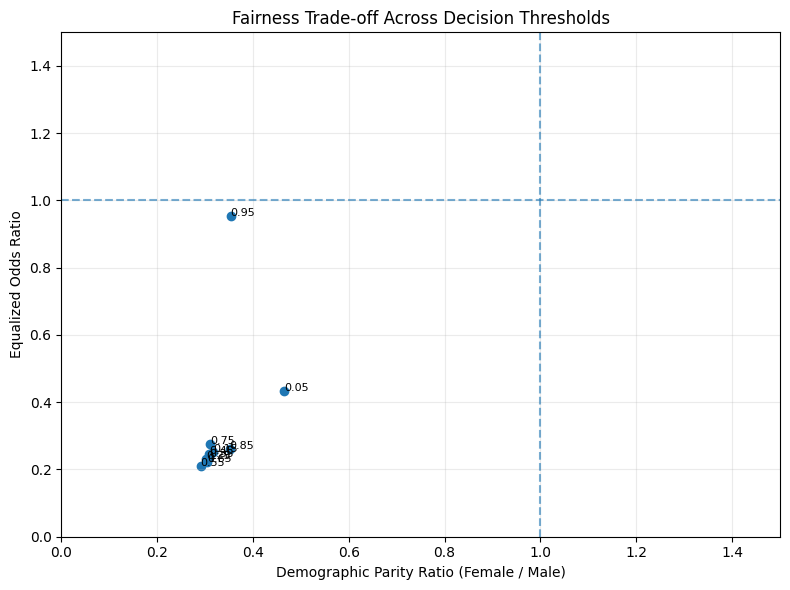

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(
    fairness_results["DP ratio (F/M)"],
    fairness_results["EO ratio"]
)

for _, row in fairness_results.iterrows():
    if pd.notna(row["DP ratio (F/M)"]) and pd.notna(row["EO ratio"]):
        plt.annotate(
            str(row["Threshold"]),
            (row["DP ratio (F/M)"], row["EO ratio"]),
            fontsize=8
        )

plt.axvline(1.0, linestyle="--", alpha=0.6)
plt.axhline(1.0, linestyle="--", alpha=0.6)

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity Ratio (Female / Male)")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-off Across Decision Thresholds")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("adult_fairness_tradeoff.png", dpi=180)
plt.show()
